# Entropy, Cross-Entropy, KL Divergence, JS Divergence, and Mutual Information

**AI Mathematics · 6. Information Theory**

Learn the information-theoretic quantities underlying classification losses, distribution comparison, representation learning, and GAN objectives.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Compute entropy and cross-entropy.
- Distinguish KL divergence from a true distance metric.
- Calculate Jensen-Shannon divergence and mutual information.

In [1]:
import numpy as np

## 1. Entropy
For a discrete distribution \(p\), entropy is \(H(p)=-\sum_i p_i\log p_i\). It is measured in nats when using natural logarithms and in bits when using base-2 logarithms. Entropy is zero for a certain outcome and largest for a uniform distribution with a fixed number of outcomes.

In [2]:
import numpy as np

def entropy(p, base=np.e):
    p = np.asarray(p, dtype=float)
    if np.any(p < 0) or not np.isclose(p.sum(), 1.0):
        raise ValueError("p must be a probability distribution")
    positive = p > 0
    return -np.sum(p[positive] * np.log(p[positive]) / np.log(base))

print("entropy [0.5, 0.5] in bits:", entropy([0.5, 0.5], base=2))
print("entropy [0.9, 0.1] in nats:", entropy([0.9, 0.1]))

entropy [0.5, 0.5] in bits: 1.0
entropy [0.9, 0.1] in nats: 0.3250829733914482


## 2. Cross-entropy and classification
Cross-entropy from target distribution \(p\) to prediction \(q\) is \(H(p,q)=-\sum_i p_i\log q_i\). For one-hot targets it becomes the negative log-probability assigned to the correct class. Confident, wrong predictions are penalized strongly.

In [3]:
def cross_entropy(p, q, eps=1e-12):
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    if np.any(p < 0) or np.any(q < 0) or not np.isclose(p.sum(), 1) or not np.isclose(q.sum(), 1):
        raise ValueError("p and q must be probability distributions")
    return -np.sum(p * np.log(np.clip(q, eps, 1.0)))

print(cross_entropy([0, 1, 0], [0.1, 0.8, 0.1]))
print(cross_entropy([0, 1, 0], [0.8, 0.1, 0.1]))

0.2231435513142097
2.3025850929940455


## 3. KL divergence
The Kullback-Leibler divergence is \(D_{KL}(p\|q)=\sum_i p_i\log(p_i/q_i)\). It is nonnegative but not symmetric, so it is not a metric. If \(p_i>0\) while \(q_i=0\), the divergence is infinite; practical code often clips probabilities or works in log space.

In [4]:
def kl_divergence(p, q, eps=1e-12):
    p = np.asarray(p, dtype=float); q = np.asarray(q, dtype=float)
    if np.any(p < 0) or np.any(q < 0) or not np.isclose(p.sum(), 1) or not np.isclose(q.sum(), 1):
        raise ValueError("p and q must be probability distributions")
    mask = p > 0
    return np.sum(p[mask] * np.log(p[mask] / np.clip(q[mask], eps, None)))

p = np.array([0.7, 0.2, 0.1]); q = np.array([0.5, 0.3, 0.2])
print("KL(p||q):", kl_divergence(p, q))
print("KL(q||p):", kl_divergence(q, p))

KL(p||q): 0.0851228259572216
KL(q||p): 0.09203285023383187


## 4. Jensen-Shannon divergence
Jensen-Shannon divergence symmetrizes KL using the midpoint distribution \(m=(p+q)/2\): \(JS(p,q)=\frac12 KL(p\|m)+\frac12 KL(q\|m)\). It is finite for distributions with zeros when handled correctly, and its square root is a metric under standard definitions. JS divergence appears in the original GAN objective.

In [5]:
def js_divergence(p, q):
    p = np.asarray(p, dtype=float); q = np.asarray(q, dtype=float)
    m = 0.5*(p+q)
    return 0.5*kl_divergence(p, m) + 0.5*kl_divergence(q, m)

print("JS(p,q):", js_divergence(p, q))
print("identical distributions:", js_divergence(p, p))

JS(p,q): 0.021901178968493855
identical distributions: 0.0


## 5. Mutual information
Mutual information measures how much knowing one variable reduces uncertainty about another: \(I(X;Y)=\sum_{x,y}p(x,y)\log\frac{p(x,y)}{p(x)p(y)}\). It is zero for independent discrete variables and is symmetric. Estimating it from high-dimensional continuous data is difficult and requires care.

In [6]:
# Joint distribution for two binary variables; rows=X, columns=Y
p_xy = np.array([[0.4, 0.1], [0.1, 0.4]])
p_x = p_xy.sum(axis=1, keepdims=True)
p_y = p_xy.sum(axis=0, keepdims=True)
ratio = p_xy / (p_x @ p_y)
mi = np.sum(p_xy * np.log(ratio))
print("mutual information in nats:", mi)

# Independent joint distribution has zero mutual information.
independent = p_x @ p_y
print("independent MI:", np.sum(independent * np.log(independent/(p_x@p_y))))

mutual information in nats: 0.19274475702175753
independent MI: 0.0


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: entropy and distribution mismatch

Entropy is high when probability mass is spread across many outcomes. Cross-entropy and KL divergence compare a target distribution with a model distribution; KL divergence is asymmetric. The small numerical epsilon below avoids taking the logarithm of zero, but probabilities should still be normalized and interpreted carefully.

entropy of [0.5, 0.5]: 1.0
entropy of [0.9, 0.1]: 0.4689955935892812


18_entropy_cross_entropy_kl_js_mutual_information.ipynb:cell15:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


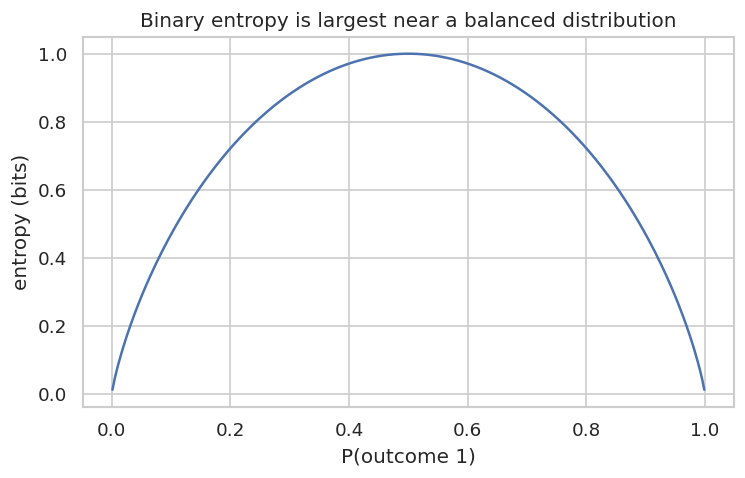

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
def viz_info_entropy(p):
    p = np.asarray(p, dtype=float); p = p[p > 0]
    return float(-np.sum(p*np.log2(p)))
viz_info_ps = np.linspace(0.001, 0.999, 300)
viz_info_H = -(viz_info_ps*np.log2(viz_info_ps) + (1-viz_info_ps)*np.log2(1-viz_info_ps))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(viz_info_ps, viz_info_H)
ax.set_xlabel("P(outcome 1)"); ax.set_ylabel("entropy (bits)"); ax.set_title("Binary entropy is largest near a balanced distribution"); plt.show()
print("entropy of [0.5, 0.5]:", viz_info_entropy([0.5, 0.5]))
print("entropy of [0.9, 0.1]:", viz_info_entropy([0.9, 0.1]))

### Compare KL and Jensen–Shannon divergence

KL divergence can be infinite if the model assigns zero probability to an event that has positive probability under the target. Jensen–Shannon divergence averages KL divergence to the midpoint distribution and is symmetric. The implementation assumes that each input is a normalized probability distribution.

18_entropy_cross_entropy_kl_js_mutual_information.ipynb:cell17:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,prediction,cross-entropy,KL(target || model),JS divergence
0,model 1,1.1568,0.0000,0.0000
1,model 2,1.4219,0.2651,0.0667
2,model 3,2.8412,1.6844,0.3651


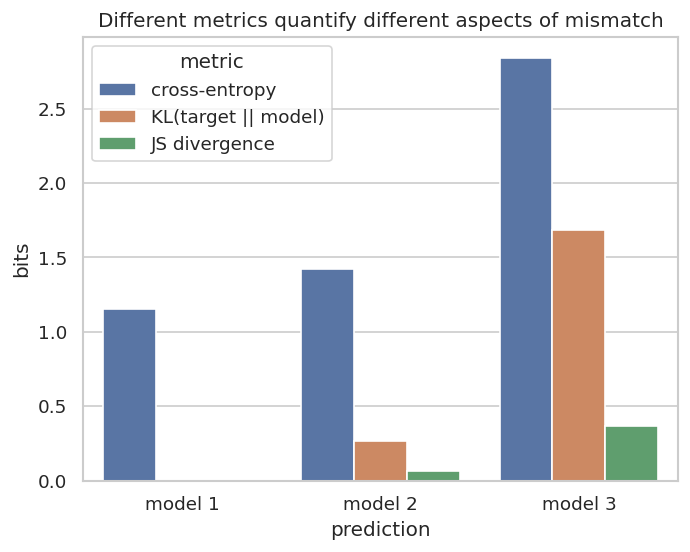

In [8]:
def viz_info_kl(p, q):
    p = np.asarray(p, dtype=float); q = np.asarray(q, dtype=float)
    if np.any((p > 0) & (q <= 0)): return np.inf
    mask = p > 0
    return float(np.sum(p[mask]*np.log2(p[mask]/q[mask])))
def viz_info_js(p, q):
    p = np.asarray(p, dtype=float); q = np.asarray(q, dtype=float)
    m = 0.5*(p+q)
    return 0.5*viz_info_kl(p, m)+0.5*viz_info_kl(q, m)
viz_info_target = np.array([0.7, 0.2, 0.1])
viz_info_preds = [np.array([0.7,0.2,0.1]), np.array([0.4,0.4,0.2]), np.array([0.1,0.2,0.7])]
viz_info_df = pd.DataFrame([{"prediction": f"model {i+1}", "cross-entropy": -np.sum(viz_info_target*np.log2(q)), "KL(target || model)": viz_info_kl(viz_info_target,q), "JS divergence": viz_info_js(viz_info_target,q)} for i,q in enumerate(viz_info_preds)])
display(viz_info_df.round(4))
sns.barplot(data=viz_info_df.melt(id_vars="prediction", var_name="metric", value_name="bits"), x="prediction", y="bits", hue="metric")
plt.title("Different metrics quantify different aspects of mismatch"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Compute entropy in bits for [0.25, 0.25, 0.25, 0.25].

In [9]:
print(entropy([0.25, 0.25, 0.25, 0.25], base=2))

2.0


### Exercise 2
Exercise 2: What is KL(p||p) for a valid distribution?

In [10]:
print(kl_divergence([0.2, 0.8], [0.2, 0.8]))

0.0


## Key takeaways
- Entropy measures uncertainty; cross-entropy penalizes probability assigned by a model to outcomes.
- KL divergence is asymmetric; Jensen-Shannon divergence is symmetric.
- Mutual information measures dependence, and is zero when discrete variables are independent.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.